# Natural frequency analysis of a cylinder

An isotropic circular cylindrical shell of `Quad4` elements, supported at
both ends by shear diaphragms, whose lowest frequencies are compared with the
three-dimensional elasticity solution tabulated by Leissa (1973). The mass
matrix is assembled with `update_M` and the frequencies are computed with
`pyfe3d.solver.natural_frequency`, see
[Linear buckling and natural frequencies](../eigenvalue_analyses.rst). The
full references are at the end of the notebook.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from numpy import isclose
from scipy.sparse import coo_matrix

from pyfe3d import DOF, DOUBLE, INT, Quad4, Quad4Data, Quad4Probe
from pyfe3d.shellprop_utils import isotropic_plate
from pyfe3d.solver import natural_frequency

## The reference values

Leissa (1973) writes the frequencies $\omega$ as the frequency parameter of
his Eq. (2.26), p. 38,

$$
\Omega^2 = \frac{\rho (1 - \nu^2) R^2 \omega^2}{E}
$$

and defines the shear diaphragm supports by his Eq. (2.33), p. 43, $v = w =
N_x = M_x = 0$ at both ends. Table 2.8 (Sec. 2.3, p. 55) gives the lowest
frequency parameters of the three-dimensional theory of elasticity, shear
diaphragms at both ends and $\nu = 0.3$. For $R/h = 20$ and $l/(m R) = 4$:

| $n$ | $\Omega$ |
|----|----------|
| 2 | 0.121249 |
| 3 | 0.129881 |

every other entry of that column being higher ($n = 1$: 0.257011, $n = 4$:
0.219098). A cylinder of length $L = 4 R$ vibrating with $m = 1$ axial
half-wave therefore has the $n = 2$ pair as its two lowest frequencies and
the $n = 3$ pair as the next two: each circumferential wave number $n \ge 1$
gives two modes of the same frequency, $\cos n\theta$ and $\sin n\theta$. A
shell theory differs from the elasticity solution: Table 2.6 (concluded),
p. 53, of the same reference puts the Flügge shell theory 0.40 % above it for
$n = 3$ at this geometry.

In [2]:
Omega_ref = {2: 0.121249, 3: 0.129881}

## The model

The parameter $\Omega$ is dimensionless, so only $R/h$, $L/R$ and $\nu$
matter: $R = 250$ mm, $h = R/20$, $L = 4 R$, $E = 70$ GPa, $\nu = 0.3$ and
$\rho = 2700$ kg/m$^3$. The axis of the cylinder is the global $z$ axis. The
mesh has `ntheta` nearly square elements around the circumference; the last
column of nodes is replaced by the first one to close the cylinder. The
element $x$ axis is set along the axis of the cylinder by the vector $(0, 0,
1)$ given to `update_rotation_matrix`, and `update_M(..., mtype=0)` gives the
consistent mass matrix.

The shear diaphragms hold the radial and the circumferential displacements
at both ends, which for a cylinder along $z$ are the global $x$ and $y$
translations, while the axial displacement and the rotations are free ($N_x =
M_x = 0$). The rigid axial translation is removed by holding the axial
displacement of a single node at mid-length, where the axial displacement of
every mode with $m = 1$ vanishes:

In [3]:
R = 0.250 # m
h = R/20 # m
L = 4*R # m
E = 70.e9 # Pa
nu = 0.3
rho = 2.7e3 # kg/m3
prop = isotropic_plate(thickness=h, E=E, nu=nu, rho=rho)

def cylinder(ntheta, num_eigvalues=6):
    data = Quad4Data()
    probe = Quad4Probe()
    nlength = int(round(ntheta*L/(2*np.pi*R)))
    nlength += 1 - nlength % 2

    nids = 1 + np.arange(nlength*(ntheta + 1))
    nids_mesh = nids.reshape(nlength, ntheta + 1)
    nids_mesh[:, -1] = nids_mesh[:, 0]
    nids = np.unique(nids_mesh)
    nid_pos = dict(zip(nids, np.arange(len(nids))))

    zlin = np.linspace(0, L, nlength)
    thetalin = np.linspace(0, 2*np.pi, ntheta + 1)[:-1][::-1]
    zmesh, thetamesh = np.meshgrid(zlin, thetalin)
    zmesh = zmesh.T
    thetamesh = thetamesh.T
    ncoords = np.vstack(((np.cos(thetamesh)*R).flatten(),
                         (np.sin(thetamesh)*R).flatten(),
                         zmesh.flatten())).T
    ncoords_flatten = ncoords.flatten()
    x, y, z = ncoords.T

    n1s = nids_mesh[:-1, :-1].flatten()
    n2s = nids_mesh[1:, :-1].flatten()
    n3s = nids_mesh[1:, 1:].flatten()
    n4s = nids_mesh[:-1, 1:].flatten()
    num_elements = len(n1s)
    N = DOF*nlength*ntheta

    KC0r = np.zeros(data.KC0_SPARSE_SIZE*num_elements, dtype=INT)
    KC0c = np.zeros(data.KC0_SPARSE_SIZE*num_elements, dtype=INT)
    KC0v = np.zeros(data.KC0_SPARSE_SIZE*num_elements, dtype=DOUBLE)
    Mr = np.zeros(data.M_SPARSE_SIZE*num_elements, dtype=INT)
    Mc = np.zeros(data.M_SPARSE_SIZE*num_elements, dtype=INT)
    Mv = np.zeros(data.M_SPARSE_SIZE*num_elements, dtype=DOUBLE)
    for k, (n1, n2, n3, n4) in enumerate(zip(n1s, n2s, n3s, n4s)):
        quad = Quad4(probe)
        quad.n1, quad.n2, quad.n3, quad.n4 = n1, n2, n3, n4
        quad.c1 = DOF*nid_pos[n1]
        quad.c2 = DOF*nid_pos[n2]
        quad.c3 = DOF*nid_pos[n3]
        quad.c4 = DOF*nid_pos[n4]
        quad.init_k_KC0 = k*data.KC0_SPARSE_SIZE
        quad.init_k_M = k*data.M_SPARSE_SIZE
        quad.update_rotation_matrix(ncoords_flatten, 0., 0., 1.)
        quad.update_probe_xe(ncoords_flatten)
        quad.update_KC0(KC0r, KC0c, KC0v, prop)
        quad.update_M(Mr, Mc, Mv, prop, mtype=0)
    KC0 = coo_matrix((KC0v, (KC0r, KC0c)), shape=(N, N)).tocsc()
    M = coo_matrix((Mv, (Mr, Mc)), shape=(N, N)).tocsc()

    # shear diaphragms at both ends, one node held axially at mid-length
    bk = np.zeros(N, dtype=bool)
    edges = isclose(z, 0) | isclose(z, L)
    bk[0::DOF][edges] = True
    bk[1::DOF][edges] = True
    middle = np.where(isclose(z, L/2))[0]
    bk[2::DOF][middle[0]] = True
    bu = ~bk

    omegan, eigvecsu = natural_frequency(KC0[bu, :][:, bu], M[bu, :][:, bu],
                                         num_eigvalues=num_eigvalues, tol=1e-8)
    eigvecs = np.zeros((N, num_eigvalues))
    eigvecs[bu] = eigvecsu
    Omega = omegan*R*np.sqrt(rho*(1 - nu**2)/E)
    return dict(Omega=Omega, eigvecs=eigvecs, ncoords=ncoords,
                thetamesh=thetamesh, zmesh=zmesh, num_elements=num_elements)

## Convergence

`natural_frequency` returns the circular frequencies sorted; the first two
are the $n = 2$ pair and the next two the $n = 3$ pair. The frequencies
converge from above:

In [4]:
print('%6s %8s %11s %11s %11s %11s %11s %11s' % ('ntheta', 'elements',
      'Omega_1', 'Omega_2', 'n=2 diff.', 'Omega_3', 'Omega_4', 'n=3 diff.'))
conv = []
for ntheta in [16, 24, 32, 48, 64, 96]:

    res = cylinder(ntheta)
    O = res['Omega']
    d2 = O[0]/Omega_ref[2] - 1
    d3 = O[2]/Omega_ref[3] - 1
    conv.append((ntheta, d2, d3))
    print('%6d %8d %11.8f %11.8f %10.2f%% %11.8f %11.8f %9.2f%%'
          % (ntheta, res['num_elements'], O[0], O[1], 100*d2, O[2], O[3],
             100*d3))

ntheta elements     Omega_1     Omega_2   n=2 diff.     Omega_3     Omega_4   n=3 diff.
    16      160  0.12580294  0.12580294       3.76%  0.15085258  0.15085258     16.15%


    24      336  0.12329016  0.12329016       1.68%  0.13850345  0.13850345      6.64%


    32      640  0.12232531  0.12232531       0.89%  0.13454988  0.13454988      3.59%


    48     1440  0.12169936  0.12169936       0.37%  0.13185390  0.13185390      1.52%


    64     2560  0.12148037  0.12148037       0.19%  0.13092776  0.13092776      0.81%


    96     5760  0.12132261  0.12132261       0.06%  0.13026712  0.13026712      0.30%


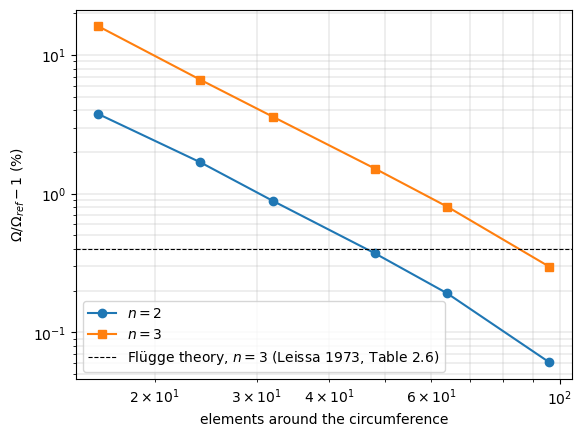

In [5]:
conv = np.array(conv)
plt.loglog(conv[:, 0], 100*conv[:, 1], 'o-', label='$n = 2$')
plt.loglog(conv[:, 0], 100*conv[:, 2], 's-', label='$n = 3$')
plt.axhline(0.40, color='k', ls='--', lw=0.8,
            label='Flügge theory, $n = 3$ (Leissa 1973, Table 2.6)')
plt.xlabel('elements around the circumference')
plt.ylabel(r'$\Omega/\Omega_{ref} - 1$ (%)')
plt.legend()
plt.grid(True, which='both', lw=0.3)
plt.show()

With 96 elements around the circumference the $n = 3$ pair is already closer
to the three-dimensional solution than the Flügge shell theory is.

## Vibration modes

The radial displacement $u_r = (x u_x + y u_y)/R$ of the first and of the
third modes of the finest mesh, on the unrolled surface: two and three full
waves around the circumference, one half-wave along the length:

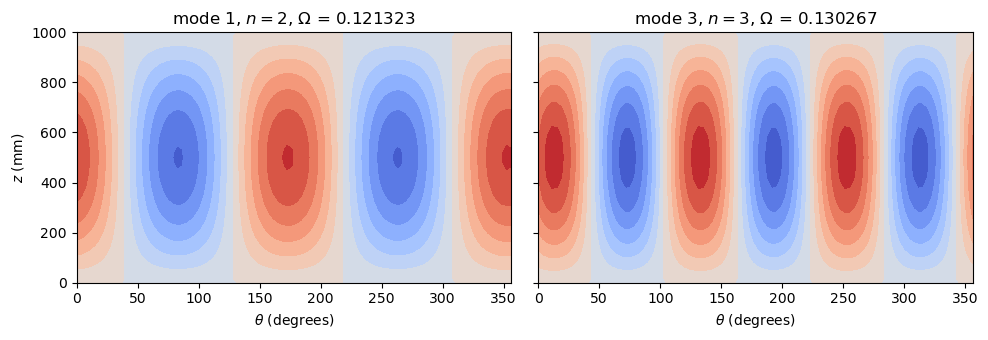

In [6]:
x, y, _ = res['ncoords'].T
fig, axs = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for ax, mode, n in zip(axs, [0, 2], [2, 3]):
    vec = res['eigvecs'][:, mode]
    ur = (x*vec[0::DOF] + y*vec[1::DOF])/R
    ur = ur.reshape(res['zmesh'].shape)
    ax.contourf(np.degrees(res['thetamesh']), res['zmesh']*1e3, ur,
                levels=12, cmap='coolwarm')
    ax.set_title(r'mode %d, $n = %d$, $\Omega$ = %.6f'
                 % (mode + 1, n, res['Omega'][mode]))
    ax.set_xlabel(r'$\theta$ (degrees)')
axs[0].set_ylabel('$z$ (mm)')
plt.tight_layout()
plt.show()

## References

- Leissa, A. W., Vibration of Shells, NASA SP-288, 1973.